# TABR datatest event-level inference — 3 models + tuning + ensemble

Evaluasi event-level untuk 3 model non-alis dan non-baseline, dengan tuning ulang threshold di data 20 subject penuh.

Output utama:
- Tabel data test event: `No`, `Kode Video`, `Kondisi`, `Label`, `Durasi`, `Jumlah Frame`
- Tabel hasil prediksi event: `No`, `Kode Video`, `Label Aktual`, `Label Prediksi`, `Status`
- Confusion matrix
- Metrik evaluasi: accuracy, recall, precision, f1-score
- Ranking model/aggregation/threshold terbaik
- Ensemble majority vote dan probability average


In [ ]:
from __future__ import annotations

import gc
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from scipy.special import expit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
from bin.tabr import Model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXP_ROOT = TABR_ROOT / 'exp' / 'tabr'
DATA_ROOT = TABR_ROOT / 'data'
MODEL_SPECS = [
    {
        'label': 'qholdout_q123_q4_q5',
        'exp_name': 'convat_apex_anxiety_qholdout_q123_q4_q5',
        'mode': 'qholdout',
        'aggregation': 'mean',
        'threshold': 0.225,
    },
    {
        'label': 'qwalk_q12_q3_q4',
        'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4',
        'mode': 'qwalkforward',
        'aggregation': 'mean',
        'threshold': 0.200,
    },
    {
        'label': 'qwalk_q123_q4_q5',
        'exp_name': 'convat_apex_anxiety_qwalk_q123_q4_q5',
        'mode': 'qwalkforward',
        'aggregation': 'mean',
        'threshold': 0.300,
    },
]
TOP_K = 3
EVENT_METHODS = ['mean', 'top3_mean', 'p90', 'max']
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.025), 3)
PRIMARY_METRIC = 'macro_f1'
FPS = 25
EVAL_ROOT = ROOT / 'output/apex/datatest/event_level_3models_report'
CM_ROOT = EVAL_ROOT / 'confusion_matrices'
EVAL_ROOT.mkdir(parents=True, exist_ok=True)
CM_ROOT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame(MODEL_SPECS))
print(f'Root: {ROOT}')
print(f'Device: {device}')


In [ ]:
FEATURE_PATHS = [
    ROOT / 'output/apex/datatest/features/15_04_2026/poc_abs_test.xlsx',
    ROOT / 'output/apex/datatest/features/17_04_2026/poc_abs_test.xlsx',
]

SELECTED_HIGH = [
    'naufal_abid_aurizky',
    'hafif_nurrahmad',
    'bisma_adhiaksa',
    'tsabita_keizya_vanya_putri',
    'raihan_daffa_izzuddin',
    'andy',
    'dicky_darmawan',
    'fata_haidar_aly',
    'muhammad_ihsan_rahmatullah',
    'raymon_devtant',
]

SELECTED_LOW = [
    'muhammad_daniel_assaqovi',
    'sileysa_faedatul_nuraini',
    'ilham_dharma_atmaja',
    'abelas_solihin',
    'dewi_anggraini_meita_sari',
    'farrel_andika_chandra',
    'muhammad_nuril_huda',
    'muhammad_rizky_firdiansyah',
    'rachmad_aprisandhy',
    'zukhrufian_abdullah',
]

SELECTED_SUBJECTS = SELECTED_HIGH + SELECTED_LOW
EXPECTED_LABEL_BY_BASE = {
    **{name: 'anxiety_tinggi' for name in SELECTED_HIGH},
    **{name: 'anxiety_rendah' for name in SELECTED_LOW},
}

def label_to_int(label: str) -> int:
    return 1 if str(label) in {'anxiety_tinggi', 'anxiety', '1', 'tinggi'} else 0


def int_to_label(value: int) -> str:
    return 'anxiety_tinggi' if int(value) == 1 else 'anxiety_rendah'


def participant_base(value: str) -> str:
    return re.sub(r'_\d+$', '', str(value))


def filter_selected_subjects(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out['participant_base'] = out['participant_raw'].map(participant_base)
    out = out[out['participant_base'].isin(SELECTED_SUBJECTS)].copy()
    out = out[out['label'] == out['participant_base'].map(EXPECTED_LABEL_BY_BASE)].copy()
    return out


def load_datatest_features(paths: list[Path]) -> pd.DataFrame:
    dfs = []
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(f'Feature file not found: {path}')
        df = pd.read_excel(path)
        if 'date' not in df.columns:
            df['date'] = path.parent.name
        dfs.append(df)
    out = pd.concat(dfs, ignore_index=True)
    out = filter_selected_subjects(out)
    out['true_label'] = out['label'].map(label_to_int).astype(int)
    out['event_key'] = (
        out['date'].astype(str) + '|' + out['participant_raw'].astype(str) + '|' + out['question'].astype(str) + '|' +
        out['sample'].astype(str) + '|' + out['event_clip'].astype(str) + '|' + out['event_no'].astype(str)
    )
    out['kode_event'] = out['sample'].astype(str) + ' / ' + out['event_clip'].astype(str)
    return out


frame_df = load_datatest_features(FEATURE_PATHS)
missing = sorted(set(SELECTED_SUBJECTS) - set(frame_df['participant_base'].unique()))
if missing:
    raise ValueError(f'Missing selected subjects: {missing}')

subject_label_counts = (
    frame_df.drop_duplicates('participant_base')['label']
    .value_counts()
    .reindex(['anxiety_tinggi', 'anxiety_rendah'], fill_value=0)
)
if subject_label_counts.to_dict() != {'anxiety_tinggi': 10, 'anxiety_rendah': 10}:
    raise ValueError(f'Expected 10 tinggi + 10 rendah, got: {subject_label_counts.to_dict()}')
print('Jumlah subjek:', subject_label_counts.to_dict())

datatest_table = (
    frame_df
    .groupby('event_key', sort=False)
    .agg(
        kode_video=('kode_event', 'first'),
        kondisi=('condition', 'first'),
        label=('label', 'first'),
        jumlah_frame=('frame', 'count'),
    )
    .reset_index(drop=True)
)
datatest_table.insert(0, 'No', np.arange(1, len(datatest_table) + 1))
datatest_table['durasi'] = datatest_table['jumlah_frame'] / FPS
datatest_table = datatest_table[['No', 'kode_video', 'kondisi', 'label', 'durasi', 'jumlah_frame']]
datatest_table = datatest_table.rename(columns={
    'kode_video': 'Kode Video',
    'kondisi': 'Kondisi',
    'label': 'Label',
    'durasi': 'Durasi',
    'jumlah_frame': 'Jumlah Frame',
})
display(Markdown('## Tabel data test event-level'))
display(datatest_table)


In [ ]:
def load_best_seed_report(exp_name: str) -> tuple[int, dict, Path]:
    eval_dir = EXP_ROOT / exp_name / '0-evaluation'
    rows = []
    for run_dir in sorted([x for x in eval_dir.iterdir() if x.is_dir() and x.name.isdigit()]):
        report_path = run_dir / 'report.json'
        if not report_path.exists():
            continue
        report = json.loads(report_path.read_text())
        rows.append((int(run_dir.name), report, run_dir))
    if not rows:
        raise FileNotFoundError(f'No report.json found for {exp_name}')
    return max(rows, key=lambda x: x[1]['metrics']['val']['score'])


def load_run_config(exp_name: str, best_seed: int, report: dict) -> dict:
    seed_toml = EXP_ROOT / exp_name / f'{best_seed}.toml'
    if seed_toml.exists():
        return lib.load_config(seed_toml)
    if 'config' in report:
        return report['config']
    tuning_toml = EXP_ROOT / exp_name / '0-tuning.toml'
    if tuning_toml.exists():
        return lib.load_config(tuning_toml)
    raise FileNotFoundError(f'No config found for {exp_name} seed {best_seed}')


def resolve_data_dir(data_path: str) -> Path:
    if data_path.startswith(':data/'):
        return DATA_ROOT / data_path.removeprefix(':data/')
    return Path(data_path)


def load_model_bundle(exp_name: str) -> dict:
    best_seed, report, best_run_dir = load_best_seed_report(exp_name)
    cfg = load_run_config(exp_name, best_seed, report)
    data_dir = resolve_data_dir(cfg['data']['path'])
    feature_cols = json.loads((data_dir / 'feature_cols.json').read_text())
    dataset = lib.build_dataset(**cfg['data']).to_torch(device)
    model = Model(
        n_num_features=dataset.n_num_features,
        n_bin_features=dataset.n_bin_features,
        cat_cardinalities=dataset.cat_cardinalities(),
        n_classes=dataset.n_classes(),
        **cfg['model'],
    ).to(device)
    checkpoint = lib.load_checkpoint(best_run_dir)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    candidate_x = {key[2:]: dataset.data[key]['train'] for key in dataset.data if key.startswith('X_')}
    candidate_y = dataset.Y['train']
    return {
        'model': model,
        'dataset': dataset,
        'candidate_x': candidate_x,
        'candidate_y': candidate_y,
        'feature_cols': feature_cols,
        'context_size': cfg['context_size'],
        'best_seed': best_seed,
        'data_path': cfg['data']['path'],
    }


def release_model_bundle(bundle: dict) -> None:
    del bundle
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [ ]:
@torch.inference_mode()
def predict_frame_probs(bundle: dict, df: pd.DataFrame, batch_size: int = 512, progress_every: int = 500) -> np.ndarray:
    feature_cols = bundle['feature_cols']
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise KeyError(f'Missing feature cols: {missing[:20]}')
    x_np = df[feature_cols].to_numpy(dtype=np.float32)
    probs = []
    total = len(x_np)
    for start in range(0, total, batch_size):
        if progress_every and start % progress_every < batch_size:
            print(f'  frame {start}/{total}')
        xb = torch.as_tensor(x_np[start:start + batch_size], device=device)
        for i in range(xb.shape[0]):
            x = {'num': xb[i:i+1]}
            logit = bundle['model'](
                x_=x,
                y=None,
                candidate_x_=bundle['candidate_x'],
                candidate_y=bundle['candidate_y'],
                context_size=bundle['context_size'],
                is_train=False,
            ).squeeze(-1).item()
            probs.append(float(expit(logit)))
    return np.asarray(probs, dtype=float)


def aggregate_probs(values, method: str, top_k: int = TOP_K) -> float:
    arr = np.asarray(list(values), dtype=float)
    if len(arr) == 0:
        return np.nan
    if method == 'mean':
        return float(np.mean(arr))
    if method == 'max':
        return float(np.max(arr))
    if method == 'p90':
        return float(np.quantile(arr, 0.90))
    if method == 'top3_mean':
        k = min(top_k, len(arr))
        return float(np.mean(np.sort(arr)[-k:]))
    raise ValueError(f'Unknown aggregation method: {method}')


In [ ]:
def make_event_predictions(frame_df: pd.DataFrame, spec: dict, method: str, threshold: float) -> pd.DataFrame:
    rows = []
    meta_cols = ['event_key', 'kode_event', 'condition', 'label', 'true_label', 'participant_base', 'participant_raw', 'question', 'sample', 'event_clip', 'event_no']
    for event_key, g in frame_df.groupby('event_key', sort=False):
        first = g.iloc[0]
        prob = aggregate_probs(g['prob_anxiety_tinggi'], method)
        row = {col: first[col] for col in meta_cols if col in g.columns}
        row.update({
            'model_label': spec['label'],
            'exp_name': spec['exp_name'],
            'aggregation': method,
            'threshold': float(threshold),
            'agg_prob_anxiety_tinggi': prob,
            'pred_label': int(prob >= threshold),
            'n_frames': len(g),
        })
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_dict(df: pd.DataFrame, spec: dict | None, method: str, threshold: float, name: str | None = None) -> dict:
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {
        'model': name or spec['label'],
        'exp_name': '' if spec is None else spec['exp_name'],
        'aggregation': method,
        'threshold': float(threshold),
        'n': len(df),
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision,
        'recall': recall,
        'f1-score': f1,
        'macro_f1': f1,
    }


def evaluate_grid(frame_df: pd.DataFrame, spec: dict) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    rows = []
    predictions = {}
    for method in EVENT_METHODS:
        base = make_event_predictions(frame_df, spec, method, threshold=0.5)
        probs = base['agg_prob_anxiety_tinggi'].to_numpy()
        for threshold in THRESHOLDS:
            pred_df = base.copy()
            pred_df['threshold'] = float(threshold)
            pred_df['pred_label'] = (probs >= float(threshold)).astype(int)
            row = metrics_dict(pred_df, spec, method, float(threshold))
            rows.append(row)
            predictions[(method, float(threshold))] = pred_df
    return pd.DataFrame(rows), predictions


def choose_best(summary_df: pd.DataFrame) -> pd.Series:
    return (
        summary_df
        .sort_values(['macro_f1', 'recall', 'accuracy'], ascending=False)
        .iloc[0]
    )


def make_prediction_table(prediction_df: pd.DataFrame) -> pd.DataFrame:
    table = prediction_df[['kode_event', 'true_label', 'pred_label']].copy()
    table.insert(0, 'No', np.arange(1, len(table) + 1))
    table['Label Aktual'] = table['true_label'].map(int_to_label)
    table['Label Prediksi'] = table['pred_label'].map(int_to_label)
    table['Status'] = np.where(table['true_label'] == table['pred_label'], 'Benar', 'Salah')
    table = table.rename(columns={'kode_event': 'Kode Video'})
    return table[['No', 'Kode Video', 'Label Aktual', 'Label Prediksi', 'Status']]


def safe_name(value: str) -> str:
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', str(value))


def plot_confusion(df: pd.DataFrame, title: str, filename: str) -> Path:
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    path = CM_ROOT / filename
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['rendah', 'tinggi'], yticklabels=['rendah', 'tinggi'], ax=ax,
    )
    ax.set_xlabel('Label Prediksi')
    ax.set_ylabel('Label Aktual')
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    return path


In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed

def run_one_model(spec: dict) -> dict:
    print(f"START {spec['label']}")
    local_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    bundle = load_model_bundle(spec['exp_name'])
    print(f"{spec['label']} best_seed={bundle['best_seed']} features={len(bundle['feature_cols'])} data_path={bundle['data_path']}")

    try:
        work = frame_df.copy()
        work['prob_anxiety_tinggi'] = predict_frame_probs(bundle, work)
        work['model_label'] = spec['label']
        work['exp_name'] = spec['exp_name']
    finally:
        release_model_bundle(bundle)

    grid_df, prediction_lookup = evaluate_grid(work, spec)
    best = choose_best(grid_df)
    best_key = (best['aggregation'], float(best['threshold']))
    prediction_df = prediction_lookup[best_key].copy()
    prediction_table = make_prediction_table(prediction_df)
    print(f"DONE {spec['label']} best={best['aggregation']} thr={float(best['threshold']):.3f} f1={float(best['macro_f1']):.4f}")
    return {
        'spec': spec,
        'frame_predictions': work,
        'grid_df': grid_df,
        'best': best.to_dict(),
        'prediction_df': prediction_df,
        'prediction_table': prediction_table,
    }

# CPU aman diparalelkan. Kalau CUDA OOM/lemot, ganti MAX_WORKERS = 1.
MAX_WORKERS = min(3, len(MODEL_SPECS)) if device.type == 'cpu' else 1
results = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(run_one_model, spec) for spec in MODEL_SPECS]
    for future in as_completed(futures):
        results.append(future.result())

results = sorted(results, key=lambda r: [s['label'] for s in MODEL_SPECS].index(r['spec']['label']))

all_grid_summary_df = pd.concat([r['grid_df'] for r in results], ignore_index=True)
best_metrics_df = pd.DataFrame([r['best'] for r in results])
best_predictions_df = pd.concat([r['prediction_df'] for r in results], ignore_index=True)
best_prediction_tables_df = pd.concat([r['prediction_table'].assign(model=r['spec']['label']) for r in results], ignore_index=True)
frame_predictions_df = pd.concat([r['frame_predictions'] for r in results], ignore_index=True)

for r in results:
    spec = r['spec']
    best = r['best']
    prediction_df = r['prediction_df']
    prediction_table = r['prediction_table']
    grid_df = r['grid_df']

    display(Markdown(f"# Model: `{spec['label']}`"))
    display(Markdown('## Ranking aggregation + threshold'))
    display(grid_df.sort_values(['macro_f1', 'recall', 'accuracy'], ascending=False).head(15).reset_index(drop=True))
    display(Markdown('## Tabel hasil prediksi event-level terbaik'))
    display(prediction_table)
    display(Markdown('## Gambar confusion matrix terbaik'))
    cm_path = plot_confusion(
        prediction_df,
        f"{spec['label']} | {best['aggregation']} | threshold={float(best['threshold']):.3f}",
        f"confusion_matrix__best__{safe_name(spec['label'])}__{best['aggregation']}__thr_{float(best['threshold']):.3f}.png",
    )
    print(f'Saved confusion matrix: {cm_path}')
    display(Markdown('## Classification report'))
    print(classification_report(
        prediction_df['true_label'].astype(int),
        prediction_df['pred_label'].astype(int),
        labels=[0, 1],
        target_names=['anxiety_rendah', 'anxiety_tinggi'],
        zero_division=0,
    ))

display(Markdown('# Best per model'))
display(best_metrics_df.sort_values(['macro_f1', 'recall', 'accuracy'], ascending=False).reset_index(drop=True))
display(Markdown('# Overall ranking'))
display(all_grid_summary_df.sort_values(['macro_f1', 'recall', 'accuracy'], ascending=False).head(30).reset_index(drop=True))


In [ ]:
display(Markdown('# Ensemble'))

wide = best_predictions_df.pivot_table(
    index='event_key',
    columns='model_label',
    values=['pred_label', 'agg_prob_anxiety_tinggi'],
    aggfunc='first',
)
base_cols = ['event_key', 'kode_event', 'condition', 'label', 'true_label']
ensemble_base = best_predictions_df.drop_duplicates('event_key')[base_cols].set_index('event_key')
pred_wide = wide['pred_label']
prob_wide = wide['agg_prob_anxiety_tinggi']

majority_df = ensemble_base.copy()
majority_df['pred_label'] = (pred_wide.mean(axis=1) >= 0.5).astype(int)
majority_df['aggregation'] = 'majority_vote'
majority_df['threshold'] = 0.5
majority_df['model_label'] = 'ensemble_majority_vote'
majority_df = majority_df.reset_index()
majority_metrics = metrics_dict(majority_df, None, 'majority_vote', 0.5, name='ensemble_majority_vote')

avg_rows = []
avg_predictions = {}
avg_prob = prob_wide.mean(axis=1).to_numpy()
for threshold in THRESHOLDS:
    avg_df = ensemble_base.copy()
    avg_df['agg_prob_anxiety_tinggi'] = avg_prob
    avg_df['pred_label'] = (avg_prob >= float(threshold)).astype(int)
    avg_df['aggregation'] = 'probability_average'
    avg_df['threshold'] = float(threshold)
    avg_df['model_label'] = 'ensemble_probability_average'
    avg_df = avg_df.reset_index()
    row = metrics_dict(avg_df, None, 'probability_average', float(threshold), name='ensemble_probability_average')
    avg_rows.append(row)
    avg_predictions[float(threshold)] = avg_df
avg_summary_df = pd.DataFrame(avg_rows)
best_avg = choose_best(avg_summary_df)
avg_df = avg_predictions[float(best_avg['threshold'])]

ensemble_metrics_df = pd.concat([pd.DataFrame([majority_metrics]), avg_summary_df], ignore_index=True)
best_ensemble_df = pd.concat([pd.DataFrame([majority_metrics]), pd.DataFrame([best_avg.to_dict()])], ignore_index=True)

display(Markdown('## Ensemble ranking'))
display(ensemble_metrics_df.sort_values(['macro_f1', 'recall', 'accuracy'], ascending=False).head(20).reset_index(drop=True))

display(Markdown('## Confusion matrix — majority vote'))
plot_confusion(majority_df, 'Ensemble majority vote', 'confusion_matrix__ensemble_majority_vote.png')

display(Markdown('## Confusion matrix — probability average terbaik'))
plot_confusion(
    avg_df,
    f"Ensemble probability average | threshold={float(best_avg['threshold']):.3f}",
    f"confusion_matrix__ensemble_probability_average__thr_{float(best_avg['threshold']):.3f}.png",
)

ensemble_predictions_df = pd.concat([majority_df, avg_df], ignore_index=True)
ensemble_prediction_tables_df = pd.concat([
    make_prediction_table(majority_df).assign(model='ensemble_majority_vote'),
    make_prediction_table(avg_df).assign(model='ensemble_probability_average'),
], ignore_index=True)


# Balance check — recall rendah vs tinggi

## qwalk_q12_q3_q4 + p90 around 0.500–0.550

,model,aggregation,threshold,tn,fp,fn,tp,accuracy,macro_f1,recall_rendah,recall_tinggi,recall_gap,balance_score
0,qwalk_q12_q3_q4,p90,0.500,178,144,153,217,0.570809,0.569442,0.552795,0.586486,0.033691,0.535750
1,qwalk_q12_q3_q4,p90,0.525,191,131,166,204,0.570809,0.570658,0.593168,0.551351,0.041816,0.528841
2,qwalk_q12_q3_q4,p90,0.550,205,117,177,193,0.575145,0.575017,0.636646,0.521622,0.115024,0.459992


## Most balanced candidates, minimum recall_gap

,model,aggregation,threshold,tn,fp,fn,tp,accuracy,macro_f1,recall_rendah,recall_tinggi,recall_gap,balance_score
0,qwalk_q123_q4_q5,p90,0.850,162,160,184,186,0.502890,0.502292,0.503106,0.502703,0.000403,0.501889
1,qwalk_q123_q4_q5,mean,0.525,160,162,186,184,0.497110,0.496504,0.496894,0.497297,0.000403,0.496101
2,qwalk_q123_q4_q5,top3_mean,0.850,161,161,186,184,0.498555,0.498000,0.500000,0.497297,0.002703,0.495298
3,qholdout_q123_q4_q5,top3_mean,0.500,162,160,182,188,0.505780,0.505082,0.503106,0.508108,0.005003,0.500079
4,qwalk_q12_q3_q4,max,0.700,174,148,167,203,0.544798,0.543997,0.540373,0.548649,0.008276,0.535721
5,qholdout_q123_q4_q5,max,0.675,168,154,173,197,0.527457,0.526625,0.521739,0.532432,0.010693,0.515932
6,qwalk_q12_q3_q4,mean,0.250,182,140,168,202,0.554913,0.554541,0.565217,0.545946,0.019271,0.535270
7,qholdout_q123_q4_q5,mean,0.225,166,156,172,198,0.526012,0.524996,0.515528,0.535135,0.019607,0.505389
8,qwalk_q12_q3_q4,top3_mean,0.525,184,138,166,204,0.560694,0.560326,0.571429,0.551351,0.020077,0.540249
9,qholdout_q123_q4_q5,p90,0.475,157,165,181,189,0.500000,0.498929,0.487578,0.510811,0.023233,0.475695


## Best balance_score = macro_f1 - recall_gap

,model,aggregation,threshold,tn,fp,fn,tp,accuracy,macro_f1,recall_rendah,recall_tinggi,recall_gap,balance_score
0,qwalk_q12_q3_q4,top3_mean,0.525,184,138,166,204,0.560694,0.560326,0.571429,0.551351,0.020077,0.540249
1,qwalk_q12_q3_q4,p90,0.500,178,144,153,217,0.570809,0.569442,0.552795,0.586486,0.033691,0.535750
2,qwalk_q12_q3_q4,max,0.700,174,148,167,203,0.544798,0.543997,0.540373,0.548649,0.008276,0.535721
3,qwalk_q12_q3_q4,mean,0.250,182,140,168,202,0.554913,0.554541,0.565217,0.545946,0.019271,0.535270
4,qwalk_q12_q3_q4,p90,0.525,191,131,166,204,0.570809,0.570658,0.593168,0.551351,0.041816,0.528841
5,qholdout_q123_q4_q5,max,0.675,168,154,173,197,0.527457,0.526625,0.521739,0.532432,0.010693,0.515932
6,qholdout_q123_q4_q5,mean,0.225,166,156,172,198,0.526012,0.524996,0.515528,0.535135,0.019607,0.505389
7,qwalk_q123_q4_q5,p90,0.850,162,160,184,186,0.502890,0.502292,0.503106,0.502703,0.000403,0.501889
8,qholdout_q123_q4_q5,top3_mean,0.500,162,160,182,188,0.505780,0.505082,0.503106,0.508108,0.005003,0.500079
9,qwalk_q123_q4_q5,mean,0.525,160,162,186,184,0.497110,0.496504,0.496894,0.497297,0.000403,0.496101


## Confusion matrix kandidat seimbang: qwalk_q12_q3_q4 + p90 + threshold 0.500

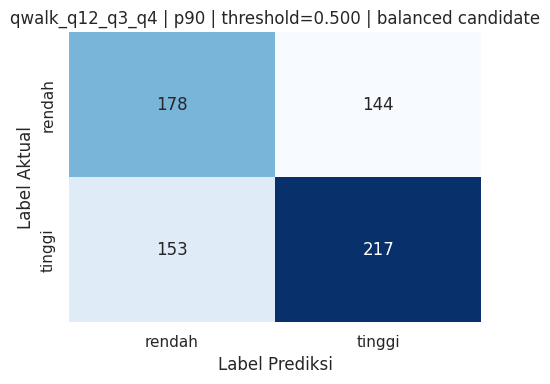

,model,exp_name,aggregation,threshold,n,tn,fp,fn,tp,accuracy,precision,recall,f1-score,macro_f1
0,qwalk_q12_q3_q4,convat_apex_anxiety_qwalk_q12_q3_q4,p90,0.5,692,178,144,153,217,0.570809,0.569436,0.569641,0.569442,0.569442


In [9]:
display(Markdown('# Balance check — recall rendah vs tinggi'))

balance_df = all_grid_summary_df.copy()
balance_df['recall_rendah'] = balance_df['tn'] / (balance_df['tn'] + balance_df['fp'])
balance_df['recall_tinggi'] = balance_df['tp'] / (balance_df['tp'] + balance_df['fn'])
balance_df['recall_gap'] = (balance_df['recall_rendah'] - balance_df['recall_tinggi']).abs()
balance_df['balance_score'] = balance_df['macro_f1'] - balance_df['recall_gap']

qwalk_p90 = balance_df[
    (balance_df['model'] == 'qwalk_q12_q3_q4')
    & (balance_df['aggregation'] == 'p90')
].copy()

display(Markdown('## qwalk_q12_q3_q4 + p90 around 0.500–0.550'))
display(
    qwalk_p90[qwalk_p90['threshold'].isin([0.500, 0.525, 0.550])]
    [[
        'model', 'aggregation', 'threshold', 'tn', 'fp', 'fn', 'tp',
        'accuracy', 'macro_f1', 'recall_rendah', 'recall_tinggi', 'recall_gap', 'balance_score',
    ]]
    .sort_values('threshold')
    .reset_index(drop=True)
)

display(Markdown('## Most balanced candidates, minimum recall_gap'))
display(
    balance_df.sort_values(['recall_gap', 'macro_f1', 'accuracy'], ascending=[True, False, False])
    [[
        'model', 'aggregation', 'threshold', 'tn', 'fp', 'fn', 'tp',
        'accuracy', 'macro_f1', 'recall_rendah', 'recall_tinggi', 'recall_gap', 'balance_score',
    ]]
    .head(20)
    .reset_index(drop=True)
)

display(Markdown('## Best balance_score = macro_f1 - recall_gap'))
display(
    balance_df.sort_values(['balance_score', 'macro_f1', 'accuracy'], ascending=[False, False, False])
    [[
        'model', 'aggregation', 'threshold', 'tn', 'fp', 'fn', 'tp',
        'accuracy', 'macro_f1', 'recall_rendah', 'recall_tinggi', 'recall_gap', 'balance_score',
    ]]
    .head(20)
    .reset_index(drop=True)
)

balanced_pick = qwalk_p90.loc[(qwalk_p90['threshold'] - 0.500).abs().idxmin()]
display(Markdown('## Confusion matrix kandidat seimbang: qwalk_q12_q3_q4 + p90 + threshold 0.500'))
balanced_source = best_predictions_df[best_predictions_df['model_label'] == 'qwalk_q12_q3_q4'].copy()
# Rebuild from frame predictions so threshold 0.500 uses the real p90 probabilities, not best threshold labels.
qwalk_frames = frame_predictions_df[frame_predictions_df['model_label'] == 'qwalk_q12_q3_q4'].copy()
balanced_pred_df = make_event_predictions(
    qwalk_frames,
    {'label': 'qwalk_q12_q3_q4', 'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4'},
    'p90',
    0.500,
)
plot_confusion(
    balanced_pred_df,
    'qwalk_q12_q3_q4 | p90 | threshold=0.500 | balanced candidate',
    'confusion_matrix__balanced_candidate__qwalk_q12_q3_q4__p90__thr_0.500.png',
)
display(pd.DataFrame([metrics_dict(
    balanced_pred_df,
    {'label': 'qwalk_q12_q3_q4', 'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4'},
    'p90',
    0.500,
)]))


In [ ]:
with pd.ExcelWriter(EVAL_ROOT / 'event_level_3models_tuned_report.xlsx') as writer:
    datatest_table.to_excel(writer, sheet_name='tabel_datatest_event', index=False)
    best_prediction_tables_df.to_excel(writer, sheet_name='tabel_prediksi_best', index=False)
    best_metrics_df.to_excel(writer, sheet_name='best_metrics', index=False)
    all_grid_summary_df.to_excel(writer, sheet_name='grid_search_metrics', index=False)
    best_predictions_df.to_excel(writer, sheet_name='raw_best_predictions', index=False)
    frame_predictions_df.to_excel(writer, sheet_name='raw_frame_predictions', index=False)
    ensemble_metrics_df.to_excel(writer, sheet_name='ensemble_metrics', index=False)
    ensemble_prediction_tables_df.to_excel(writer, sheet_name='ensemble_prediksi', index=False)
    ensemble_predictions_df.to_excel(writer, sheet_name='raw_ensemble_predictions', index=False)

print(f'Saved: {EVAL_ROOT / "event_level_3models_tuned_report.xlsx"}')
